# Cleaning Data

**Task:** DA3  
**Data provenance:** Deliberately dirtied UCI Online Retail sample; introduced defects are documented.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
print("DATA PROVENANCE: 5,000-row sample from UCI Online Retail; deliberate corruption is applied reproducibly for this cleaning exercise.")

source=load_online_retail()

raw=source.sample(n=min(5000,len(source)),random_state=SEED).reset_index(drop=True)

raw=raw.rename(columns={"InvoiceNo":"invoice_id","StockCode":"product_id","Description":"description",
        "Quantity":"quantity","InvoiceDate":"invoice_date","UnitPrice":"unit_price","CustomerID":"customer_id"})

dirty=raw.copy()

dirty["invoice_id"]=dirty["invoice_id"].astype("string")

dirty["description"]=dirty["description"].astype("string")

dirty["invoice_date"]=dirty["invoice_date"].astype("string")

dirty["unit_price"]=dirty["unit_price"].astype("string")

dirty.loc[dirty.index[:20],"description"]=dirty.loc[dirty.index[:20],"description"].str.lower().str.strip()

dirty.loc[dirty.index[20:30],"invoice_date"]="not-a-date"

dirty.loc[dirty.index[30:40],"unit_price"]="unknown"

dirty.loc[dirty.index[40:55],"customer_id"]=np.nan

dirty=pd.concat([dirty,dirty.iloc[:25]],ignore_index=True)

expected_types={"invoice_id":"string","product_id":"string","description":"string",
        "quantity":"int64","invoice_date":"datetime64[ns]","unit_price":"float64","customer_id":"string"}

expected_types["quantity"] = "int64" if pd.api.types.is_integer_dtype(raw["quantity"]) else "float64"

def dtype_accuracy(frame):
        return sum(str(frame[column].dtype)==dtype for column,dtype in expected_types.items())

numeric_raw=dirty.copy()

numeric_raw["quantity"]=pd.to_numeric(numeric_raw["quantity"],errors="coerce")

numeric_raw["unit_price"]=pd.to_numeric(numeric_raw["unit_price"],errors="coerce")

quality={
        "nulls_by_column":dirty.isna().sum(),
        "duplicate_rows":int(dirty.duplicated().sum()),
        "invalid_dates":int(pd.to_datetime(dirty["invoice_date"],errors="coerce").isna().sum()),
        "invalid_unit_prices":int(pd.to_numeric(dirty["unit_price"],errors="coerce").isna().sum()),
        "negative_quantities":int((numeric_raw["quantity"]<0).sum()),
        "dtype_accuracy":dtype_accuracy(dirty),
    }

print("Before-cleaning quality report:\nNulls by column:\n",quality["nulls_by_column"])

print("Exact duplicates:",quality["duplicate_rows"],"| invalid dates:",quality["invalid_dates"],
          "| invalid unit prices:",quality["invalid_unit_prices"],"| dtype accuracy:",
          f'{quality["dtype_accuracy"]}/{len(expected_types)}')

DATA PROVENANCE: 5,000-row sample from UCI Online Retail; deliberate corruption is applied reproducibly for this cleaning exercise.


Before-cleaning quality report:
Nulls by column:
 invoice_id         0
product_id         0
description       14
quantity           0
invoice_date       0
unit_price         0
customer_id     1279
Country            0
dtype: int64
Exact duplicates: 25 | invalid dates: 15 | invalid unit prices: 10 | dtype accuracy: 3/7


## Model Training / Analysis
Perform the task-specific analytical transformation and interpret its results; this assignment uses analysis rather than a supervised predictive model.

In [3]:
df=dirty.drop_duplicates().copy()

df["invoice_id"]=df["invoice_id"].astype("string")

df["product_id"]=df["product_id"].astype("string").str.strip()

df["description"]=df["description"].astype("string").str.strip().str.replace(r"\s+"," ",regex=True)

df["customer_id"]=df["customer_id"].astype("string").str.replace(r"\.0$","",regex=True)

df["invoice_date"]=pd.to_datetime(df["invoice_date"],errors="coerce")

df["quantity"]=pd.to_numeric(df["quantity"],errors="coerce")

df["unit_price"]=pd.to_numeric(df["unit_price"],errors="coerce")

invalid_date_rows=int(df["invoice_date"].isna().sum())

df=df.dropna(subset=["invoice_date"])

missing_customers=int(df["customer_id"].isna().sum())

df["description"]=df["description"].fillna("Unknown product")

df["quantity"]=df["quantity"].fillna(df["quantity"].median())

df["unit_price"]=df["unit_price"].fillna(df["unit_price"].median())

outlier_counts={}

for column in ("quantity","unit_price"):
        q1,q3=df[column].quantile([.25,.75]); iqr=q3-q1
        outlier_counts[column]=int(((df[column]<q1-1.5*iqr)|(df[column]>q3+1.5*iqr)).sum())

expected_types["invoice_date"]="datetime64[ns]"

expected_types["customer_id"]="string"

after_nulls=int(df.isna().sum().sum())

after_duplicate_count=int(df.duplicated().sum())

summary=pd.DataFrame({
        "before":[len(dirty),int(dirty.isna().sum().sum()),quality["duplicate_rows"],f'{quality["dtype_accuracy"]}/{len(expected_types)}'],
        "after":[len(df),after_nulls,after_duplicate_count,f'{dtype_accuracy(df)}/{len(expected_types)}'],
    },index=["rows","null_cells","duplicate_rows","dtype_accuracy"])

print("Cleaning decisions: remove exact duplicates; parse dates and discard the 10 deliberately invalid-date rows; retain customer IDs as nullable strings rather than inventing IDs; normalize whitespace; median-impute the 10 deliberately invalid unit prices; retain legitimate returns and IQR-flag unusual values for review.")

print("Dropped for invalid dates:",invalid_date_rows,"; missing customer IDs retained:",missing_customers)

print("IQR outliers retained for review:",outlier_counts)

print("Before vs after summary:\n",summary)

print("Final data types:\n",df.dtypes)

path=OUT_DIR/"cleaned_online_retail_sample.csv"

df.to_csv(path,index=False)

print("Saved cleaned sample:",path)

print(df.head().to_string(index=False))

Cleaning decisions: remove exact duplicates; parse dates and discard the 10 deliberately invalid-date rows; retain customer IDs as nullable strings rather than inventing IDs; normalize whitespace; median-impute the 10 deliberately invalid unit prices; retain legitimate returns and IQR-flag unusual values for review.
Dropped for invalid dates: 10 ; missing customer IDs retained: 1274
IQR outliers retained for review: {'quantity': 535, 'unit_price': 345}
Before vs after summary:
                before after
rows             5025  4990
null_cells       1293  1274
duplicate_rows     25     0
dtype_accuracy    3/7   5/7
Final data types:
 invoice_id              string
product_id              string
description             string
quantity                 int64
invoice_date    datetime64[us]
unit_price             Float64
customer_id             string
Country                    str
dtype: object
Saved cleaned sample: D:\Oasis\DataAnalytics-L1-DataCleaning\outputs\cleaned_online_retail_sampl

## Visualizations
Compare the data-quality indicators measured before and after the documented cleaning steps.

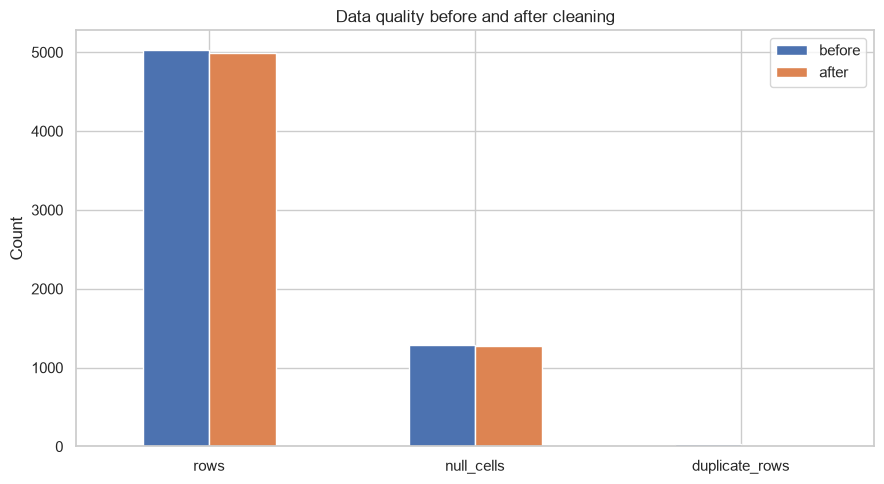

In [4]:
quality_plot = summary.loc[['rows', 'null_cells', 'duplicate_rows']].apply(pd.to_numeric, errors='coerce')
quality_plot.plot.bar(figsize=(9, 5), title='Data quality before and after cleaning')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Chart 1 interpretation
The before/after comparison shows which quality dimensions changed during the documented cleaning process. Imputed values and retained business outliers still warrant review.

## Model Training / Analysis
Summarize the analytical results and limitations. This task uses descriptive analysis rather than a supervised predictive model.

## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [5]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'Data Cleaning and Quality Assessment',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,before,after
rows,5025,4990
null_cells,1293,1274
duplicate_rows,25,0
dtype_accuracy,3/7,5/7


Saved 1 chart(s) and evaluation summary: D:\Oasis\DataAnalytics-L1-DataCleaning\outputs\evaluation_summary.csv
